In [1]:
pip install pandas numpy matplotlib seaborn streamlit  plotly jupyter

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.2.1 -> 26.2.2
[notice] To update, run: C:\Users\Erkai\AppData\Local\Programs\Python\Python313\python.exe -m pip install --upgrade pip


In [2]:
# Copstone  Option B: Logistics, Delivery & Returns Insights
##Question:** How well are we delivering, and what causes returns?
##Benjedick Cristobal** **Python Programming DSA- Batch 4**

In [3]:
import pandas as pd, numpy as np
import matplotlib.pyplot as plt, seaborn as sns
import seaborn as sns
import matplotlib.pyplot as plt

raw = "../data/raw/"

In [4]:
customers = pd.read_csv(raw + "customers.csv", dtype={"phone": str})
products = pd.read_csv(raw + "products.csv")
orders = pd.read_csv(raw + "orders.csv")
items = pd.read_csv(raw + "order_items.csv")
payments = pd.read_csv(raw + "payments.csv")
shipments = pd.read_csv(raw + "shipments.csv")
returns = pd.read_csv(raw + "returns.csv")

tables = {"customers": customers,
          "products":  products,
          "orders": orders,
          "order_items": items,
          "payments": payments,
          "shipments": shipments,
          "returns":returns}

In [5]:
print("customers:", customers.shape)
print("products:", products.shape)
print("orders:", orders.shape)
print("items:", items.shape)
print("payments:", payments.shape)
print("returns:", returns.shape)

customers: (5050, 13)
products: (800, 9)
orders: (15075, 8)
items: (37763, 5)
payments: (15000, 6)
returns: (1200, 6)


In [6]:
customers.head(10)

,customer_id,first_name,last_name,gender,age,email,phone,region_code,region_name,city,barangay,signup_date,loyalty_tier
0,CUST000001,Grace,DelosReyes,NaN,20.0,grace.delosreyes95@outlook.com,09196001338,Region III,Central Luzon,Angeles,Brgy 1,2025-12-31,Bronze
1,CUST000002,Ana,Ramos,Female,35.0,ana.ramos@companymail.ph,09026542351,CARAGA,Caraga,Butuan,Brgy 9,2025-02-08,Bronze
2,CUST000003,Arvin,Navarro,Male,14.0,arvin.navarrooutlook.com,09161849593,NCR,Metro Manila,Pasig,Brgy 2,2023-09-10,Bronze
3,CUST000004,Kyle,Rivera,F,26.0,kyle.rivera13@outlook.com,09752553419,Region III,Central Luzon,Angeles,Brgy 1,2024-11-17,NaN
4,CUST000005,Juan,Mendoza,Male,29.0,juan.mendoza@gmail.com,09350305641,Region III,Central Luzon,Angeles,Brgy 9,2023-01-21,Gold
5,CUST000006,Jasmine,Reyes,Female,31.0,jasmine.reyes@companymail.ph,09388496965,Region IV-A,CALABARZON,San Pablo,Brgy 6,2025-08-13,Gold
6,CUST000007,Juan,Diaz,F,18.0,juan.diaz@companymail.ph,09691669784,Region IV-A,CALABARZON,Dasmariñas,Brgy 9,2025-10-22,Bronze
7,CUST000008,Leo,Navarro,Unknown,28.0,leo.navarro@companymail.ph,09270482814,CARAGA,Caraga,Butuan,Brgy 2,2025-09-22,NaN
8,CUST000009,Kyle,Castillo,F,36.0,kyle.castillo@companymail.ph,09957015430,Region III,Central Luzon,Olongapo,Brgy 10,2025-12-12,Bronze
9,CUST000010,Mia,Castillo,M,32.0,mia.castillo99@gmail.com,09782489638,Region IV-A,CALABARZON,San Pablo,Brgy 2,2024-06-04,Gold


In [7]:
customers.info()

<class 'pandas.DataFrame'>
RangeIndex: 5050 entries, 0 to 5049
Data columns (total 13 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   customer_id   5050 non-null   str    
 1   first_name    5050 non-null   str    
 2   last_name     5050 non-null   str    
 3   gender        4749 non-null   str    
 4   age           4900 non-null   float64
 5   email         4943 non-null   str    
 6   phone         4903 non-null   str    
 7   region_code   5050 non-null   str    
 8   region_name   5050 non-null   str    
 9   city          5050 non-null   str    
 10  barangay      5050 non-null   str    
 11  signup_date   5050 non-null   str    
 12  loyalty_tier  4784 non-null   str    
dtypes: float64(1), str(12)
memory usage: 1.0 MB


In [8]:
print("Blank values per column:")
print(customers.isna().sum())
print()
print("Fully duplicated rows:", customers.duplicated().sum())

Blank values per column:
customer_id       0
first_name        0
last_name         0
gender          301
age             150
email           107
phone           147
region_code       0
region_name       0
city              0
barangay          0
signup_date       0
loyalty_tier    266
dtype: int64

Fully duplicated rows: 50


In [9]:
cleaning_log = []

def log(table, issue, action, rows):
    cleaning_log.append({"table": table, "issue": issue,
                        "action": action, "rows_affected": int(rows)})

In [10]:
customers_clean = customers.copy()
print("Rows before:", len(customers_clean))

Rows before: 5050


In [11]:
before = len(customers_clean)
customers_clean  = customers_clean.drop_duplicates(subset="customer_id")
removed = before - len(customers_clean)

print("Duplicates remove:", removed)
print("Rows now:", len(customers_clean))
log("customers", "duplicate customer_id", "kept first row", removed)


Duplicates remove: 50
Rows now: 5000


In [12]:
print(customers_clean["gender"].value_counts(dropna=False))

gender
M          1297
F          1263
Female      721
Male        719
Unknown     587
NaN         298
female      115
Name: count, dtype: int64


In [13]:
customers_clean["gender"] = customers_clean["gender"].fillna("Unknown")
customers_clean["gender"] = customers_clean["gender"].str.strip().str.lower()
customers_clean["gender"] = customers_clean["gender"].replace({
    "m": "Male", "male": "Male",
    "f": "Female", "female": "Female",
    "unknown": "Unknown" })

print(customers_clean["gender"].value_counts())
log("customers", "messy gender labesl and blanks", "standardized to Male/Female/Unknown", len(customers_clean))

gender
Female     2099
Male       2016
Unknown     885
Name: count, dtype: int64


In [14]:
null_age = customers_clean["age"] < 0
print("Negative ages found:", null_age.sum())

customers_clean.loc[null_age, "age"] = np.nan

print("Smallest age now:", customers_clean["age"].min())
log("customers", "negative age", "set to blank (NaN)", null_age.sum())

Negative ages found: 48
Smallest age now: 0.0


In [15]:
customers_clean["email_valid"] = customers_clean["email"].str.contains("@", na=False)

print(customers_clean["email_valid"].value_counts())
log("customers", "missing or wrong email", "added email_valid column",
        (customers_clean["email_valid"]).sum())

email_valid
True     4777
False     223
Name: count, dtype: int64


In [16]:
customers_clean["phone_valid"] = customers_clean["phone"].str.len() == 11

print(customers_clean["phone_valid"].value_counts())
log("customers", "missing or short number", "added phone_valid column",
        (~customers_clean["phone_valid"]).sum())


phone_valid
True     4722
False     278
Name: count, dtype: int64


In [17]:
customers_clean["signup_date"] = pd.to_datetime(
customers_clean["signup_date"], format="mixed", errors="coerce")
print("Unreadable dates:", customers_clean["signup_date"].isna().sum())
print(customers_clean["signup_date"].dtype)
log("customers", "mixed date formats", "converted to real dates", len(customers_clean))

Unreadable dates: 0
datetime64[us]


In [18]:
blank_tiers = customers_clean["loyalty_tier"].isna().sum()
customers_clean["loyalty_tier"] = customers_clean["loyalty_tier"].fillna("None")
print(customers_clean["loyalty_tier"].value_counts())
log("customers", "blank loyalty_tier", "filled with None", blank_tiers)

loyalty_tier
Bronze      2204
Silver      1257
Gold         915
Platinum     360
None         264
Name: count, dtype: int64


In [19]:
print(customers_clean.shape)
customers_clean.head(3)

(5000, 15)


,customer_id,first_name,last_name,gender,age,email,phone,region_code,region_name,city,barangay,signup_date,loyalty_tier,email_valid,phone_valid
0,CUST000001,Grace,DelosReyes,Unknown,20.0,grace.delosreyes95@outlook.com,09196001338,Region III,Central Luzon,Angeles,Brgy 1,2025-12-31,Bronze,True,True
1,CUST000002,Ana,Ramos,Female,35.0,ana.ramos@companymail.ph,09026542351,CARAGA,Caraga,Butuan,Brgy 9,2025-02-08,Bronze,True,True
2,CUST000003,Arvin,Navarro,Male,14.0,arvin.navarrooutlook.com,09161849593,NCR,Metro Manila,Pasig,Brgy 2,2023-09-10,Bronze,False,True


In [20]:
products_clean = products.copy()
print(products_clean["category"].value_counts())

category
Beauty              94
Toys                92
Books               90
Fashion             89
Groceries           77
Home & Kitchen      76
Sports              74
Electronics         71
electronics         20
Book                20
Home and Kitchen    19
Electronics         17
Grocery             12
Elec                11
Beauty & Care       11
Toy                 11
Fashon               8
Sports & Outdoor     8
Name: count, dtype: int64


In [21]:
old_category = products_clean["category"].copy()
products_clean["category"] = products_clean["category"].str.strip().str.lower()
products_clean["category"] = products_clean["category"].replace({
"beauty & care": "Beauty", "beauty": "Beauty",
"toy": "Toys", "toys": "Toys",
"book": "Books", "books": "Books",
"fashon": "Fashion", "fashion": "Fashion",
"grocery": "Groceries", "groceries": "Groceries",
"home and kitchen": "Home & Kitchen", "home & kitchen": "Home & Kitchen",
"sports & outdoor": "Sports", "sports": "Sports",
"elec": "Electronics", "electronics": "Electronics"})
changed = (old_category != products_clean["category"]).sum()
print(products_clean["category"].value_counts())
log("products", "inconsistent category labels", "mapped to 8 clean categories", changed)

category
Electronics       119
Books             110
Beauty            105
Toys              103
Fashion            97
Home & Kitchen     95
Groceries          89
Sports             82
Name: count, dtype: int64


In [22]:
products_clean["category"].unique()

<ArrowStringArray>
[        'Beauty', 'Home & Kitchen',        'Fashion',           'Toys',
          'Books',      'Groceries',    'Electronics',         'Sports']
Length: 8, dtype: str

In [23]:
products_clean["unit_cost"] = (products_clean["unit_cost"].astype("string")
.str.replace("[^0-9.]", "", regex=True))
products_clean["unit_price"] = (products_clean["unit_price"].astype("string")
.str.replace("[^0-9.]", "", regex=True))
products_clean["unit_cost"] = pd.to_numeric(products_clean["unit_cost"], errors="coerce")
products_clean["unit_price"] = pd.to_numeric(products_clean["unit_price"], errors="coerce")
print(products_clean[["unit_cost", "unit_price"]].describe())
log("products", "currency stored as text", "converted to numbers", len(products_clean))

       unit_cost  unit_price
count      800.0       800.0
mean   60.889275    93.23515
std    30.585252   49.856278
min         10.0       18.43
25%      39.7825      59.345
50%       54.345      81.385
75%        75.89    119.0425
max       264.82      438.77


In [24]:
products_clean["uom"] = products_clean["uom"].replace({"pcs": "pc", "piece": "pc"})
print(products_clean["uom"].value_counts())

uom
pc        429
pack      125
bottle    123
set       123
Name: count, dtype: int64


In [25]:
blank_stock = products_clean["stock_qty"].isna().sum()
middle = products_clean["stock_qty"].median()
products_clean["stock_qty"] = products_clean["stock_qty"].fillna(middle)
print("Filled", blank_stock, "blanks with", middle)
log("products", "missing stock_qty", "filled with median", blank_stock)

Filled 19 blanks with 118.0


In [26]:
products_clean["launch_date"] = pd.to_datetime(
products_clean["launch_date"], format="mixed", errors="coerce")
print(products_clean.shape)
products_clean.head(3)

(800, 9)


,product_id,product_name,brand,category,unit_cost,unit_price,stock_qty,uom,launch_date
0,PROD00001,KidJoy Beauty 963,KidJoy,Beauty,44.17,64.5,125.0,pc,2022-01-18
1,PROD00002,HomeEase Home 368,HomeEase,Home & Kitchen,37.18,70.39,131.0,pc,2022-11-25
2,PROD00003,FreshCart Fashion 911,FreshCart,Fashion,46.29,70.26,41.0,pc,2023-09-04


In [27]:
orders_clean = orders.copy()
before = len(orders_clean)
orders_clean = orders_clean.drop_duplicates(subset="order_id")
removed = before - len(orders_clean)
print("Duplicate orders removed:", removed)
print("Unique orders now:", len(orders_clean))
log("orders", "duplicate order_id", "kept first row", removed)

Duplicate orders removed: 75
Unique orders now: 15000


In [28]:
orders_clean["order_datetime"] = pd.to_datetime(
orders_clean["order_datetime"], format="mixed", errors="coerce")
print(orders_clean["order_datetime"].dtype)
print("Unreadable:", orders_clean["order_datetime"].isna().sum())
log("orders", "mixed datetime formats", "parsed with format=mixed", len(orders_clean))

datetime64[us]
Unreadable: 0


In [29]:
blank_disc = orders_clean["discount_pct"].isna().sum()
orders_clean["discount_pct"] = orders_clean["discount_pct"].fillna(0)
log("orders", "missing discount_pct", "filled with 0", blank_disc)
blank_fee = orders_clean["shipping_fee"].isna().sum()
orders_clean["shipping_fee"] = orders_clean["shipping_fee"].fillna(orders_clean["shipping_fee"].median())
log("orders", "missing shipping_fee", "filled with median", blank_fee)
print("Blank discounts filled:", blank_disc, "| Blank fees filled:", blank_fee)

Blank discounts filled: 756 | Blank fees filled: 470


In [30]:
orders_clean["customer_found"] = orders_clean["customer_id"].isin(customers_clean["customer_id"])
missing_customers = (~orders_clean["customer_found"]).sum()
print("Orders with an unknown customer:", missing_customers)
log("orders", "unknown customer_id", "flagged customer_found=False (kept)", missing_customers)

Orders with an unknown customer: 43


In [31]:
print(orders_clean.shape)
orders_clean.head(3)

(15000, 9)


,order_id,customer_id,order_datetime,order_status,sales_channel,shipping_method,discount_pct,shipping_fee,customer_found
0,ORD0000001,CUST000839,2025-11-07 17:02:00,Cancelled,Marketplace,Standard,0.074,102.68,True
1,ORD0000002,CUST002871,2025-09-18 09:13:00,Completed,Marketplace,Express,0.063,0.00,True
2,ORD0000003,CUST000720,2025-08-08 04:59:00,Completed,Web,Standard,0.137,103.83,True


In [32]:
items_clean = items.copy()
before = len(items_clean)
items_clean = items_clean.drop_duplicates()
removed = before - len(items_clean)
print("Duplicate rows removed:", removed)
log("order_items", "duplicate rows", "dropped exact duplicates", removed)

Duplicate rows removed: 262


In [33]:
zero_qty = (items_clean["quantity"] <= 0).sum()
items_clean = items_clean[items_clean["quantity"] > 0]
print("Rows with quantity 0 removed:", zero_qty)
log("order_items", "quantity = 0 (invalid)", "dropped rows", zero_qty)

Rows with quantity 0 removed: 372


In [34]:
known = items_clean["product_id"].isin(products_clean["product_id"])
missing_items = (~known).sum()
items_clean = items_clean[known]
print("Missing product rows removed:", missing_items)
log("order_items", "orphan product_id", "dropped rows", missing_items)

Missing product rows removed: 127


In [35]:
items_clean["unit_price_at_purchase"] = (items_clean["unit_price_at_purchase"].astype("string")
.str.replace("[^0-9.]", "", regex=True))
items_clean["unit_price_at_purchase"] = pd.to_numeric(
items_clean["unit_price_at_purchase"], errors="coerce")
print("Blank prices:", items_clean["unit_price_at_purchase"].isna().sum())

Blank prices: 2208


In [36]:
price_lookup = products_clean.set_index("product_id")["unit_price"]
blank_prices = items_clean["unit_price_at_purchase"].isna().sum()
items_clean["unit_price_at_purchase"] = items_clean["unit_price_at_purchase"].fillna(
items_clean["product_id"].map(price_lookup))
print("Blank prices before:", blank_prices)
print("Blank prices after:", items_clean["unit_price_at_purchase"].isna().sum())
log("order_items", "missing unit_price_at_purchase", "backfilled from products", blank_prices)

Blank prices before: 2208
Blank prices after: 0


In [37]:
items_clean["line_total"] = items_clean["quantity"] * items_clean["unit_price_at_purchase"]
print(items_clean.shape)
items_clean.head(3)

(37002, 6)


,order_item_id,order_id,product_id,quantity,unit_price_at_purchase,line_total
0,ITEM000000001,ORD0000001,PROD00513,2,120.67,241.34
1,ITEM000000002,ORD0000002,PROD00124,2,83.58,167.16
2,ITEM000000003,ORD0000002,PROD00631,2,46.96,93.92


In [38]:
shipments_clean = shipments.copy()
shipments_clean["ship_date"] = pd.to_datetime(
shipments_clean["ship_date"], format="mixed", errors="coerce")
shipments_clean["delivered_date"] = pd.to_datetime(
shipments_clean["delivered_date"], format="mixed", errors="coerce")

print("Blank delivered dates:", shipments_clean["delivered_date"].isna().sum())
log("shipments", "mixed date formats", "parsed with format=mixed", len(shipments_clean))

Blank delivered dates: 729


In [39]:
shipments_clean["courier"] = shipments_clean["courier"].str.strip()
shipments_clean["shipment_status"] = shipments_clean["shipment_status"].str.strip()
print(shipments_clean["shipment_status"].value_counts())

shipment_status
Delivered             11680
In Transit             2694
Returned to Sender      465
Lost                    161
Name: count, dtype: int64


In [40]:
shipments_clean["lead_time_days"] = (
shipments_clean["delivered_date"] - shipments_clean["ship_date"]).dt.days
print(shipments_clean["lead_time_days"].describe())

count    14271.000000
mean         3.997968
std          1.991026
min          1.000000
25%          2.000000
50%          4.000000
75%          6.000000
max          7.000000
Name: lead_time_days, dtype: float64


In [41]:
negative = (shipments_clean["lead_time_days"] < 0).sum()
print("Negative lead times:", negative)
shipments_clean.loc[shipments_clean["lead_time_days"] < 0, "lead_time_days"] = np.nan
log("shipments", "negative lead time", "set to blank", negative)

Negative lead times: 0


In [42]:
not_delivered = shipments_clean["shipment_status"] != "Delivered"
has_date = shipments_clean["delivered_date"].notna()
contradict = (not_delivered & has_date).sum()
print("Not Delivered but has a delivered date:", contradict)
log("shipments", "delivered_date present but status not Delivered",
"excluded from lead-time stats", contradict)

Not Delivered but has a delivered date: 3149


In [43]:
shipments_clean["lead_time_valid"] = np.where(
shipments_clean["shipment_status"] == "Delivered",
shipments_clean["lead_time_days"],
np.nan)
print("Trusted lead times:", shipments_clean["lead_time_valid"].notna().sum())
print("Average lead time:", round(shipments_clean["lead_time_valid"].mean(), 2))

Trusted lead times: 11122
Average lead time: 4.0


In [44]:
returns_clean = returns.copy()
returns_clean["return_request_date"] = pd.to_datetime(
returns_clean["return_request_date"], format="mixed", errors="coerce")
returns_clean["reason"] = returns_clean["reason"].str.strip().str.title()
blank_flag = returns_clean["refunded_flag"].isna().sum()
returns_clean["refunded_flag"] = returns_clean["refunded_flag"].fillna("Unknown")
log("returns", "blank refunded_flag", "filled with Unknown", blank_flag)
blank_refund = returns_clean["refund_amount"].isna().sum()
log("returns", "missing refund_amount", "left blank (not guessed)", blank_refund)
print(returns_clean["reason"].value_counts())

reason
Changed Mind     182
Defective        178
Missing Parts    175
Size Issue       174
Late Delivery    169
Wrong Item       162
Damaged Item     160
Name: count, dtype: int64


In [45]:
unknown_orders = (~returns_clean["order_id"].isin(orders_clean["order_id"])).sum()
print("Returns with an unknown order:", unknown_orders)
log("returns", "orphan order_id", "none found", unknown_orders)

Returns with an unknown order: 0


In [46]:
payments_clean = payments.copy()
payments_clean["payment_date"] = pd.to_datetime(
payments_clean["payment_date"], format="mixed", errors="coerce")
payments_clean["amount_paid"] = (payments_clean["amount_paid"].astype("string")
.str.replace("[^0-9.]", "", regex=True))
payments_clean["amount_paid"] = pd.to_numeric(payments_clean["amount_paid"], errors="coerce")
log("payments", "currency text and mixed dates", "converted", len(payments_clean))
print(payments_clean.shape)

(15000, 6)


In [47]:
pd.set_option("display.max_colwidth", 70)
log_df = pd.DataFrame(cleaning_log)
log_df

,table,issue,action,rows_affected
0,customers,duplicate customer_id,kept first row,50
1,customers,messy gender labesl and blanks,standardized to Male/Female/Unknown,5000
2,customers,negative age,set to blank (NaN),48
3,customers,missing or wrong email,added email_valid column,4777
4,customers,missing or short number,added phone_valid column,278
5,customers,mixed date formats,converted to real dates,5000
6,customers,blank loyalty_tier,filled with None,264
7,products,inconsistent category labels,mapped to 8 clean categories,137
8,products,currency stored as text,converted to numbers,800
9,products,missing stock_qty,filled with median,19


In [48]:
out = "../data/cleaned/"
customers_clean.to_csv(out + "cleaned_customers.csv", index=False)
products_clean.to_csv(out + "cleaned_products.csv", index=False)
orders_clean.to_csv(out + "cleaned_orders.csv", index=False)
items_clean.to_csv(out + "cleaned_order_items.csv", index=False)
shipments_clean.to_csv(out + "cleaned_shipments.csv", index=False)
returns_clean.to_csv(out + "cleaned_returns.csv", index=False)
payments_clean.to_csv(out + "cleaned_payments.csv", index=False)
log_df.to_csv(out + "cleaning_log.csv", index=False)
print("Saved!")

Saved!


In [49]:
status_pct = shipments_clean["shipment_status"].value_counts(normalize=True) * 100
print(status_pct.round(1))

shipment_status
Delivered             77.9
In Transit            18.0
Returned to Sender     3.1
Lost                   1.1
Name: proportion, dtype: float64


In [50]:
lead = shipments_clean["lead_time_valid"].dropna()
# print("Parcels counted:", len(lead))
# print("Average lead time:", round(lead.mean(), 2), "days")
# print("Median lead time:", lead.median(), "days")
# print("Fastest:", lead.min(), "| Slowest:", lead.max())

In [51]:
shipments_clean["is_delivered"] = shipments_clean["shipment_status"] == "Delivered"
shipments_clean["is_lost"] = shipments_clean["shipment_status"] == "Lost"
shipments_clean["is_returned"] = shipments_clean["shipment_status"] == "Returned to Sender"

In [52]:
courier_perf = shipments_clean.groupby("courier").agg(
shipments=("shipment_id", "count"),
avg_lead_days=("lead_time_valid", "mean"),
pct_delivered=("is_delivered", "mean"),
pct_lost=("is_lost", "mean"),
pct_returned=("is_returned", "mean"))
courier_perf["pct_delivered"] = courier_perf["pct_delivered"] * 100
courier_perf["pct_lost"] = courier_perf["pct_lost"] * 100
courier_perf["pct_returned"] = courier_perf["pct_returned"] * 100
courier_perf = courier_perf.round(2)
courier_perf

,shipments,avg_lead_days,pct_delivered,pct_lost,pct_returned
courier,,,,,
2GO,2951,4.01,77.43,1.05,3.08
GrabExpress,3011,4.03,78.31,1.16,2.92
J&T,3042,4.02,76.59,1.25,3.58
LBC,3011,3.98,78.55,1.06,2.79
NinjaVan,2985,3.97,78.46,0.84,3.12


In [53]:
total_orders = orders_clean["order_id"].nunique()
returned_orders = returns_clean["order_id"].nunique()
return_rate = returned_orders / total_orders * 100
print("Total orders:", total_orders)
print("Returned orders:", returned_orders)
print("Return rate:", round(return_rate, 2), "%")

Total orders: 15000
Returned orders: 1200
Return rate: 8.0 %


In [54]:
reason_counts = returns_clean["reason"].value_counts()
print(reason_counts)

reason
Changed Mind     182
Defective        178
Missing Parts    175
Size Issue       174
Late Delivery    169
Wrong Item       162
Damaged Item     160
Name: count, dtype: int64


In [55]:
controllable = ["Defective", "Missing Parts", "Wrong Item", "Damaged Item", "Late Delivery"]
is_controllable = returns_clean["reason"].isin(controllable)
share = is_controllable.mean() * 100
print("Controllable returns:", is_controllable.sum(), "of", len(returns_clean))
print("Share:", round(share, 1), "%")

Controllable returns: 844 of 1200
Share: 70.3 %


In [56]:
shipments_clean["returned"] = shipments_clean["order_id"].isin(returns_clean["order_id"])
courier_return = shipments_clean.groupby("courier")["returned"].mean() * 100
courier_return = courier_return.round(2).sort_values(ascending=False)
print(courier_return)

courier
NinjaVan       8.81
J&T            8.61
GrabExpress    8.44
LBC            7.11
2GO            7.01
Name: returned, dtype: float64


In [57]:
order_category = items_clean.merge(products_clean[["product_id", "category"]], on="product_id")
order_category = order_category[["order_id", "category"]].drop_duplicates()
order_category["returned"] = order_category["order_id"].isin(returns_clean["order_id"])
category_return = order_category.groupby("category")["returned"].mean() * 100
category_return = category_return.round(2).sort_values(ascending=False)
print(category_return)

category
Home & Kitchen    8.65
Fashion           8.47
Sports            8.25
Beauty            8.24
Books             7.83
Electronics       7.72
Toys              7.62
Groceries         7.47
Name: returned, dtype: float64


In [58]:
 import seaborn as sns

In [59]:
import matplotlib.pyplot as plt

In [60]:
import os
os.makedirs("../charts", exist_ok=True)
sns.set_theme(style="whitegrid")
BLUE = "#2563eb"

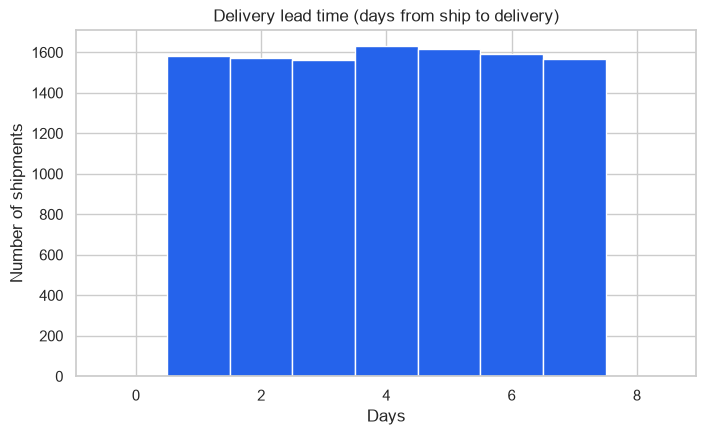

In [61]:
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.hist(lead, bins=range(0, 10), color=BLUE, edgecolor="white", align="left")
ax.set_title("Delivery lead time (days from ship to delivery)")
ax.set_xlabel("Days")
ax.set_ylabel("Number of shipments")
fig.savefig("../charts/1_lead_time_distribution.png", dpi=150, bbox_inches="tight")
plt.show()

In [62]:
#There is no sharp peak, delivery is unpredictable. Lead times are spread evenly between 1 and 7 days.
#With an average of 4 days.

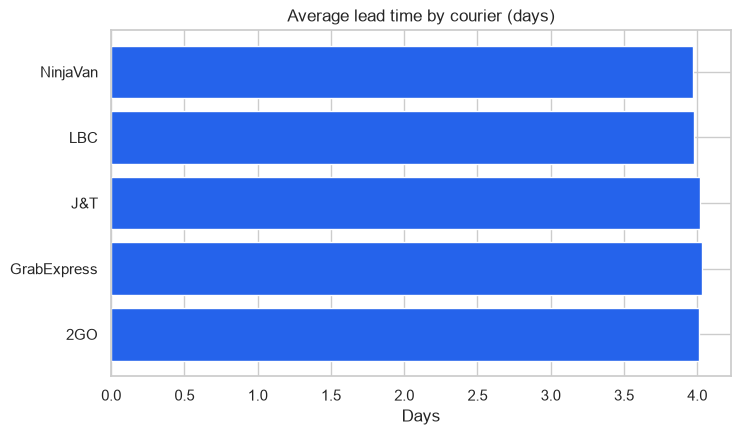

In [63]:
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.barh(courier_perf.index, courier_perf["avg_lead_days"], color=BLUE)
ax.set_title("Average lead time by courier (days)")
ax.set_xlabel("Days")
fig.savefig("../charts/2_courier_comparison.png", dpi=150, bbox_inches="tight")
plt.show()

In [64]:
#All five couriers average about 4 days

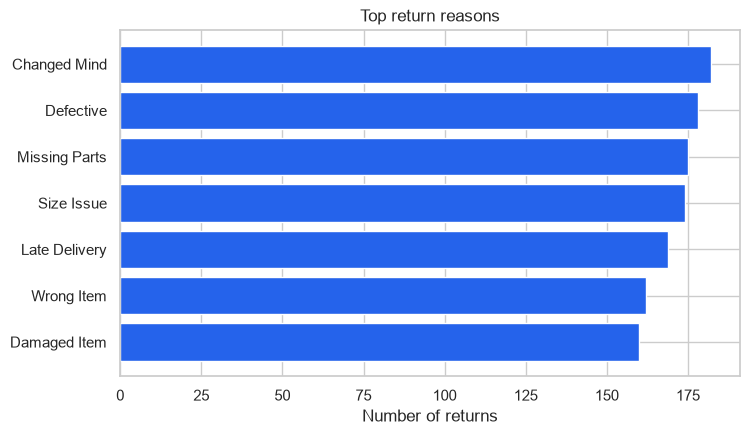

In [65]:
fig, ax = plt.subplots(figsize=(8, 4.5))
reasons_sorted = reason_counts.sort_values()
ax.barh(reasons_sorted.index, reasons_sorted.values, color=BLUE)
ax.set_title("Top return reasons")
ax.set_xlabel("Number of returns")
fig.savefig("../charts/3_return_reasons.png", dpi=150, bbox_inches="tight")
plt.show()

In [71]:
#Change of Mind is the top reaason. But five of the seven reasons are things the business can control.
#Spread almost evenly 

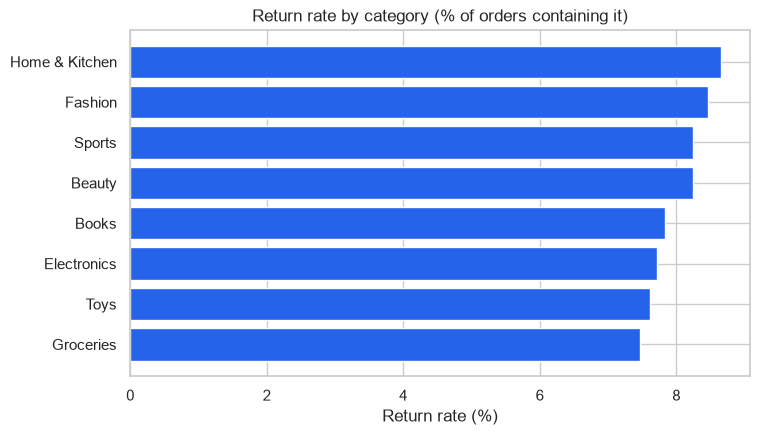

In [67]:
fig, ax = plt.subplots(figsize=(8, 4.5))
cat_sorted = category_return.sort_values()
ax.barh(cat_sorted.index, cat_sorted.values, color=BLUE)
ax.set_title("Return rate by category (% of orders containing it)")
ax.set_xlabel("Return rate (%)")
fig.savefig("../charts/4_return_rate_by_category.png", dpi=150, bbox_inches="tight")
plt.show()

In [68]:
#Home & Kitchen has the highest return rate of 8.7%.
#Groceries are the lowest  with 7.5%.

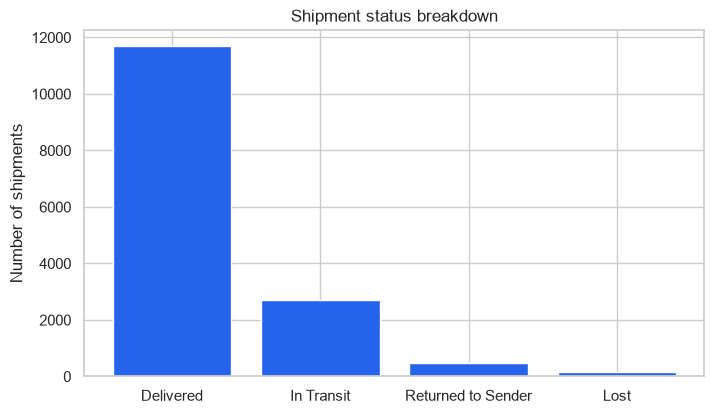

In [69]:
fig, ax = plt.subplots(figsize=(8, 4.5))
status_counts = shipments_clean["shipment_status"].value_counts()
ax.bar(status_counts.index, status_counts.values, color=BLUE)
ax.set_title("Shipment status breakdown")
ax.set_ylabel("Number of shipments")
fig.savefig("../charts/5_shipment_status.png", dpi=150, bbox_inches="tight")
plt.show()

In [70]:
#77.9% of shipments delivered, 18% still in Transit.
#3.1% were returned to sender, and 1.07% were lost.